# Parse F2A Exempt Cutoff Dates

This notebook extracts the separate F2A exempt cutoff dates from the Visa Bulletin PDFs.

The F2A exempt cutoff date appears in a note below the Final Action Dates table in some bulletins. It is separate from the regular F2A cutoff dates shown in the main table.

The goal is to:

1. Search all 120 Visa Bulletin PDFs
2. Extract bulletins that contain a separate F2A exempt cutoff date
3. Convert the cutoff value into a real date
4. Sort the records chronologically
5. Save the result as a separate CSV

In [1]:
import re
import calendar
from pathlib import Path

import pandas as pd
import pdfplumber

In [2]:
# Find the main project folder.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw_pdfs"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

print("PDF count:", len(list(RAW_DIR.rglob("*.pdf"))))

PDF count: 120


In [3]:
MONTHS = {
    month.lower(): number
    for number, month in enumerate(calendar.month_name)
    if month
}


def get_bulletin_date(pdf_path):
    month_name, year = pdf_path.stem.rsplit("_", 1)

    month_number = MONTHS[month_name.lower()]

    date = pd.Timestamp(
        year=int(year),
        month=month_number,
        day=1
    )

    return date + pd.offsets.MonthEnd(0)

## Extract F2A Exempt Cutoff Dates

The F2A exempt cutoff date appears in a note below the Final Action Dates table in some Visa Bulletins.

This section searches all 120 PDFs, extracts the separate exempt cutoff date when it exists, converts it into a real date, and organizes the results chronologically.

In [4]:
# Search all Visa Bulletin PDFs for a separate F2A exempt cutoff date.

exempt_records = []

# Pattern for the special monthly F2A exempt note.
# The date uses the DDMMMYY format, such as 01DEC14.
EXEMPT_PATTERN = re.compile(
    r"F2A NUMBERS EXEMPT FROM (?:THE )?PER-COUNTRY LIMIT"
    r".{0,700}?"
    r"(\d{2}[A-Z]{3}\d{2})"
)

for pdf_path in RAW_DIR.rglob("*.pdf"):

    # Extract all text from the PDF.
    with pdfplumber.open(pdf_path) as pdf:
        text = " ".join(
            page.extract_text() or ""
            for page in pdf.pages
        )

    # Remove line breaks and extra spaces and make the text uppercase
    # so the note can be searched consistently.
    clean_text = " ".join(text.split()).upper()

    match = EXEMPT_PATTERN.search(clean_text)

    if match:
        exempt_records.append({
            "bulletin_date": get_bulletin_date(pdf_path),
            "exempt_cutoff_value": match.group(1),
            "source_file": pdf_path.name
        })

In [5]:
# Convert the extracted records into a DataFrame.
exempt_df = pd.DataFrame(exempt_records)

print("F2A exempt cutoff dates found:", len(exempt_df))

exempt_df.head()

F2A exempt cutoff dates found: 77


,bulletin_date,exempt_cutoff_value,source_file
0,2022-08-31,22APR19,august_2022.pdf
1,2022-09-30,22APR19,september_2022.pdf
2,2025-01-31,15MAY21,january_2025.pdf
3,2025-04-30,15MAY21,april_2025.pdf
4,2025-10-31,01FEB23,october_2025.pdf


In [6]:
# Convert values such as 01DEC14 into real dates such as 2014-12-01.
exempt_df["exempt_cutoff_date"] = pd.to_datetime(
    exempt_df["exempt_cutoff_value"],
    format="%d%b%y"
)

In [7]:
# Sort the records chronologically by bulletin month.
exempt_df = (
    exempt_df
    .sort_values("bulletin_date")
    .reset_index(drop=True)
)

exempt_df.head(10)

,bulletin_date,exempt_cutoff_value,source_file,exempt_cutoff_date
0,2016-10-31,01DEC14,october_2016.pdf,2014-12-01
1,2016-11-30,08JAN15,november_2016.pdf,2015-01-08
2,2016-12-31,15FEB15,december_2016.pdf,2015-02-15
3,2017-01-31,08MAR15,january_2017.pdf,2015-03-08
4,2017-02-28,01APR15,february_2017.pdf,2015-04-01
5,2017-03-31,22APR15,march_2017.pdf,2015-04-22
6,2017-04-30,22MAY15,april_2017.pdf,2015-05-22
7,2017-05-31,22JUN15,may_2017.pdf,2015-06-22
8,2017-06-30,22JUL15,june_2017.pdf,2015-07-22
9,2017-07-31,22AUG15,july_2017.pdf,2015-08-22


In [8]:
# Validate the extracted exempt dataset.
print("Records:", len(exempt_df))
print("Unique bulletin months:", exempt_df["bulletin_date"].nunique())
print("Duplicate bulletin months:", exempt_df["bulletin_date"].duplicated().sum())

Records: 77
Unique bulletin months: 77
Duplicate bulletin months: 0


In [ ]:
# Spot-check October 2016 against the original PDF.
exempt_df[
    exempt_df["bulletin_date"] == pd.Timestamp("2016-10-31")
]

,bulletin_date,exempt_cutoff_value,source_file,exempt_cutoff_date
0,2016-10-31,01DEC14,october_2016.pdf,2014-12-01


In [ ]:
# Keep only the variables needed for the supplementary dataset.
f2a_exempt_df = exempt_df[
    [
        "bulletin_date",
        "exempt_cutoff_date"
    ]
].copy()

# Save the F2A exempt dates as a separate CSV.
output_path = PROCESSED_DIR / "f2a_exempt_dates.csv"

f2a_exempt_df.to_csv(
    output_path,
    index=False,
    date_format="%Y-%m-%d"
)

print("Saved to:", output_path)
print("Dataset shape:", f2a_exempt_df.shape)

Saved to: /Users/serratak/Desktop/visa-bulletin-project/visa-bulletin-project/data/processed/f2a_exempt_dates.csv
Dataset shape: (77, 2)


In [14]:
# Load the full transformed Visa Bulletin dataset
full_df = pd.read_csv(
    "../data/processed/visa_bulletins_transformed_full.csv",
    parse_dates=["bulletin_date", "cutoff_date"]
)

# Keep only F2A Final Action records
f2a_regular = full_df[
    (full_df["visa_category"] == "F2A") &
    (full_df["table_type"] == "Final Action")
][
    [
        "bulletin_date",
        "chargeability_area",
        "cutoff_date",
    ]
].copy()

f2a_regular.head()

,bulletin_date,chargeability_area,cutoff_date
1320,2016-10-31,All Chargeability Areas Except Those Listed,2014-12-22
1321,2016-11-30,All Chargeability Areas Except Those Listed,2015-01-22
1322,2016-12-31,All Chargeability Areas Except Those Listed,2015-02-22
1323,2017-01-31,All Chargeability Areas Except Those Listed,2015-03-22
1324,2017-02-28,All Chargeability Areas Except Those Listed,2015-04-15


In [19]:
# Match regular F2A Final Action dates with exempt cutoff dates
f2a_comparison = f2a_regular.merge(
    exempt_df[
        ["bulletin_date", "exempt_cutoff_date"]
    ],
    on="bulletin_date",
    how="inner"
)

f2a_comparison.head()

,bulletin_date,chargeability_area,cutoff_date,exempt_cutoff_date
0,2016-10-31,All Chargeability Areas Except Those Listed,2014-12-22,2014-12-01
1,2016-11-30,All Chargeability Areas Except Those Listed,2015-01-22,2015-01-08
2,2016-12-31,All Chargeability Areas Except Those Listed,2015-02-22,2015-02-15
3,2017-01-31,All Chargeability Areas Except Those Listed,2015-03-22,2015-03-08
4,2017-02-28,All Chargeability Areas Except Those Listed,2015-04-15,2015-04-01


In [20]:
print("Exempt bulletins:", exempt_df["bulletin_date"].nunique())
print("Comparison rows:", len(f2a_comparison))
print("Expected rows:", exempt_df["bulletin_date"].nunique() * 5)

Exempt bulletins: 77
Comparison rows: 385
Expected rows: 385


In [21]:
# How far the regular F2A Final Action cutoff is behind the bulletin date
f2a_comparison["regular_days_behind"] = (
    f2a_comparison["bulletin_date"]
    - f2a_comparison["cutoff_date"]
).dt.days

# How far the exempt cutoff is behind the bulletin date
f2a_comparison["exempt_days_behind"] = (
    f2a_comparison["bulletin_date"]
    - f2a_comparison["exempt_cutoff_date"]
).dt.days

# Difference between the regular and exempt cutoff dates
# Positive value = regular cutoff is later than exempt cutoff
f2a_comparison["cutoff_gap_days"] = (
    f2a_comparison["cutoff_date"]
    - f2a_comparison["exempt_cutoff_date"]
).dt.days

In [23]:
f2a_comparison[
    [
        "bulletin_date",
        "chargeability_area",
        "cutoff_date",
        "exempt_cutoff_date",
        "regular_days_behind",
        "exempt_days_behind",
        "cutoff_gap_days"
    ]
].head(77)

,bulletin_date,chargeability_area,cutoff_date,exempt_cutoff_date,regular_days_behind,exempt_days_behind,cutoff_gap_days
0,2016-10-31,All Chargeability Areas Except Those Listed,2014-12-22,2014-12-01,679,700,21
1,2016-11-30,All Chargeability Areas Except Those Listed,2015-01-22,2015-01-08,678,692,14
2,2016-12-31,All Chargeability Areas Except Those Listed,2015-02-22,2015-02-15,678,685,7
3,2017-01-31,All Chargeability Areas Except Those Listed,2015-03-22,2015-03-08,681,695,14
4,2017-02-28,All Chargeability Areas Except Those Listed,2015-04-15,2015-04-01,685,699,14
...,...,...,...,...,...,...,...
72,2026-05-31,All Chargeability Areas Except Those Listed,2024-08-01,2023-08-01,668,1034,366
73,2026-06-30,All Chargeability Areas Except Those Listed,2025-01-01,2024-01-01,545,911,366
74,2026-07-31,All Chargeability Areas Except Those Listed,2025-01-01,2024-01-01,576,942,366
75,2026-08-31,All Chargeability Areas Except Those Listed,2026-07-22,2025-07-22,40,405,365


In [24]:
print("Total comparison rows:", len(f2a_comparison))
print("Unique bulletins:", f2a_comparison["bulletin_date"].nunique())
print("Unique chargeability areas:", f2a_comparison["chargeability_area"].nunique())

print(
    f2a_comparison["chargeability_area"].value_counts()
)

Total comparison rows: 385
Unique bulletins: 77
Unique chargeability areas: 5
chargeability_area
All Chargeability Areas Except Those Listed    77
China                                          77
India                                          77
Mexico                                         77
Philippines                                    77
Name: count, dtype: int64


In [27]:
# Save the F2A regular vs exempt comparison dataset

''' f2a_comparison = f2a_comparison.sort_values(
    ["bulletin_date", "chargeability_area"]
).reset_index(drop=True) 

f2a_comparison.to_csv(
    "../data/processed/f2a_regular_vs_exempt_comparison.csv",
    index=False
) '''
#fail

' f2a_comparison = f2a_comparison.sort_values(\n    ["bulletin_date", "chargeability_area"]\n).reset_index(drop=True) \n\nf2a_comparison.to_csv(\n    "../data/processed/f2a_regular_vs_exempt_comparison.csv",\n    index=False\n) '

In [29]:
# Summarize the difference between regular F2A Final Action
# cutoff dates and F2A exempt cutoff dates by chargeability area.

gap_summary = (
    f2a_comparison
    .groupby("chargeability_area")["cutoff_gap_days"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max"
    )
    .round(1)
)

gap_summary

,count,mean,median,min,max
chargeability_area,,,,,
All Chargeability Areas Except Those Listed,77,199.2,37.0,7,1257
China,77,199.2,37.0,7,1257
India,77,199.2,37.0,7,1257
Mexico,77,0.0,0.0,0,0
Philippines,77,199.2,37.0,7,1257


In [30]:
# Create a simplified Q1 F2A comparison table using:
# 1) All Chargeability Areas Except Those Listed as the general reference group
# 2) Mexico as a separate comparison
# 3) The F2A exempt cutoff date

general_f2a = f2a_comparison[
    f2a_comparison["chargeability_area"]
    == "All Chargeability Areas Except Those Listed"
][
    [
        "bulletin_date",
        "cutoff_date",
        "exempt_cutoff_date",
        "regular_days_behind",
        "exempt_days_behind"
    ]
].copy()

general_f2a = general_f2a.rename(
    columns={
        "cutoff_date": "general_cutoff_date",
        "regular_days_behind": "general_days_behind"
    }
)

mexico_f2a = f2a_comparison[
    f2a_comparison["chargeability_area"] == "Mexico"
][
    [
        "bulletin_date",
        "cutoff_date",
        "regular_days_behind"
    ]
].copy()

mexico_f2a = mexico_f2a.rename(
    columns={
        "cutoff_date": "mexico_cutoff_date",
        "regular_days_behind": "mexico_days_behind"
    }
)

# Merge the general and Mexico F2A data by bulletin month
f2a_q1_comparison = general_f2a.merge(
    mexico_f2a,
    on="bulletin_date",
    how="inner"
)

# Calculate the difference between regular and exempt cutoff dates
f2a_q1_comparison["general_gap_days"] = (
    f2a_q1_comparison["general_cutoff_date"]
    - f2a_q1_comparison["exempt_cutoff_date"]
).dt.days

f2a_q1_comparison["mexico_gap_days"] = (
    f2a_q1_comparison["mexico_cutoff_date"]
    - f2a_q1_comparison["exempt_cutoff_date"]
).dt.days

# Put columns in a clean order
f2a_q1_comparison = f2a_q1_comparison[
    [
        "bulletin_date",
        "general_cutoff_date",
        "mexico_cutoff_date",
        "exempt_cutoff_date",
        "general_days_behind",
        "mexico_days_behind",
        "exempt_days_behind",
        "general_gap_days",
        "mexico_gap_days"
    ]
].sort_values("bulletin_date").reset_index(drop=True)

f2a_q1_comparison

,bulletin_date,general_cutoff_date,mexico_cutoff_date,exempt_cutoff_date,general_days_behind,mexico_days_behind,exempt_days_behind,general_gap_days,mexico_gap_days
0,2016-10-31,2014-12-22,2014-12-01,2014-12-01,679,700,700,21,0
1,2016-11-30,2015-01-22,2015-01-08,2015-01-08,678,692,692,14,0
2,2016-12-31,2015-02-22,2015-02-15,2015-02-15,678,685,685,7,0
3,2017-01-31,2015-03-22,2015-03-08,2015-03-08,681,695,695,14,0
4,2017-02-28,2015-04-15,2015-04-01,2015-04-01,685,699,699,14,0
...,...,...,...,...,...,...,...,...,...
72,2026-05-31,2024-08-01,2023-08-01,2023-08-01,668,1034,1034,366,0
73,2026-06-30,2025-01-01,2024-01-01,2024-01-01,545,911,911,366,0
74,2026-07-31,2025-01-01,2024-01-01,2024-01-01,576,942,942,366,0
75,2026-08-31,2026-07-22,2025-07-22,2025-07-22,40,405,405,365,0


In [31]:
print("Rows:", len(f2a_q1_comparison))
print("Unique bulletins:", f2a_q1_comparison["bulletin_date"].nunique())

Rows: 77
Unique bulletins: 77


In [32]:
f2a_q1_comparison.to_csv(
    "../data/processed/f2a_q1_comparison.csv",
    index=False
)

In [33]:
# Summary statistics for the F2A Q1 comparison

f2a_q1_summary = f2a_q1_comparison[
    [
        "general_days_behind",
        "mexico_days_behind",
        "exempt_days_behind",
        "general_gap_days",
        "mexico_gap_days"
    ]
].describe().round(1)

f2a_q1_summary

,general_days_behind,mexico_days_behind,exempt_days_behind,general_gap_days,mexico_gap_days
count,77.0,77.0,77.0,77.0,77.0
mean,902.3,1101.5,1101.5,199.2,0.0
std,394.7,425.0,425.0,254.1,0.0
min,0.0,404.0,404.0,7.0,0.0
25%,699.0,760.0,760.0,16.0,0.0
50%,790.0,1033.0,1033.0,37.0,0.0
75%,1074.0,1354.0,1354.0,365.0,0.0
max,2153.0,2585.0,2585.0,1257.0,0.0


In [34]:
# Confirm whether Mexico and exempt cutoff dates are identical
print(
    (f2a_q1_comparison["mexico_cutoff_date"]
     == f2a_q1_comparison["exempt_cutoff_date"]).all()
)

print(
    f2a_q1_comparison["mexico_gap_days"].value_counts()
)

True
mexico_gap_days
0    77
Name: count, dtype: int64


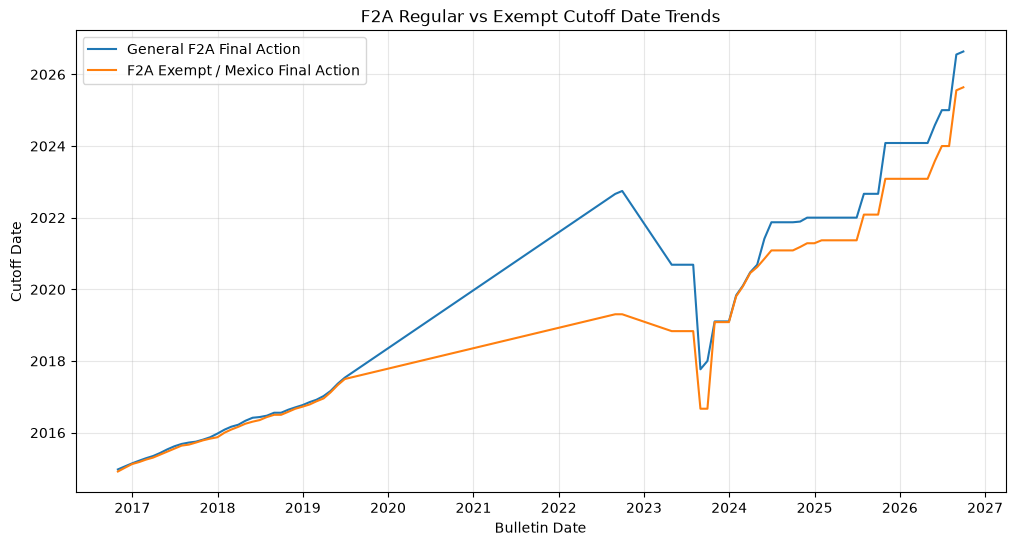

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    f2a_q1_comparison["bulletin_date"],
    f2a_q1_comparison["general_cutoff_date"],
    label="General F2A Final Action"
)

plt.plot(
    f2a_q1_comparison["bulletin_date"],
    f2a_q1_comparison["exempt_cutoff_date"],
    label="F2A Exempt / Mexico Final Action"
)

plt.xlabel("Bulletin Date")
plt.ylabel("Cutoff Date")
plt.title("F2A Regular vs Exempt Cutoff Date Trends")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

- analysis uses All Chargeability Areas Except Those Listed as the general reference
- Mexico is shown separately because its F2A Final Action cutoff differs in relevant periods
- The exempt date is interpreted as a cutoff date, meaning only priority dates earlier than that date are included.
- subject-to-per-country-limit start/end intervals are not modeled here and can be revisited later